In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [2]:
df = pd.read_excel("Cleaned_DataV4.xlsx")

In [ ]:
df.head()

In [4]:
df_clean = df.copy()

In [5]:
temp = df_clean.copy()

valid = (
    temp["Trường tốt nghiệp"].notna()
    & temp["Trường tốt nghiệp"].ne("KHÔNG Xác Định")
)

summary = (
    temp.assign(Có_dữ_liệu=valid)
    .groupby("Bậc đào tạo")
    .agg(
        Tổng=("Trường tốt nghiệp", "size"),
        Có_dữ_liệu=("Có_dữ_liệu", "sum")
    )
)

summary["Missing"] = summary["Tổng"] - summary["Có_dữ_liệu"]

summary["% Có dữ liệu"] = (
    summary["Có_dữ_liệu"] / summary["Tổng"] * 100
).round(1)

summary["% Missing"] = (
    summary["Missing"] / summary["Tổng"] * 100
).round(1)

print(summary)

              Tổng  Có_dữ_liệu  Missing  % Có dữ liệu  % Missing
Bậc đào tạo                                                     
Cao đẳng     22364       20603     1761          92.1        7.9
Trung cấp    14358        4774     9584          33.2       66.8


In [6]:
# 1. Lọc dữ liệu Cao đẳng
df_school = df_clean[
    (df_clean["Bậc đào tạo"] == "Cao đẳng") &
    (df_clean["Trường tốt nghiệp"].notna()) &
    (df_clean["Trường tốt nghiệp"] != "KHÔNG Xác Định") &
    (df_clean["Trường tốt nghiệp"] != "censored")
].copy()

print("Số sinh viên dùng để phân tích:", len(df_school))
print("Số trường:", df_school["Trường tốt nghiệp"].nunique())

Số sinh viên dùng để phân tích: 15851
Số trường: 1548


In [7]:
top20_school = (
    df_school["Trường tốt nghiệp"]
    .value_counts()
    .head(20)
)

display(top20_school)

Trường tốt nghiệp
THPT Quang Trung           192
THPT Nguyễn Huệ            181
THPT Chu Văn An            178
THPT Hùng Vương            131
THPT Nguyễn Trung Trực     130
THPT Trần Phú              119
THPT An Nhơn Tây           117
THPT Nguyễn Trãi           114
THPT Nguyễn Đình Chiểu     110
THPT Trường Chinh          110
TTGDTX Quận Tân Bình       106
THPT Phú Hòa               104
TC Bách Nghệ Tp.Hcm        102
TTGDTX Quận 12             101
THPT Tuy Phong             101
THPT Hòa Đa                100
THPT Ngô Gia Tự             98
THPT Nguyễn Du              98
TT Gdnn Và Gdtx Quận 12     97
TTGDTX Huyện Hóc Môn        96
Name: count, dtype: int64

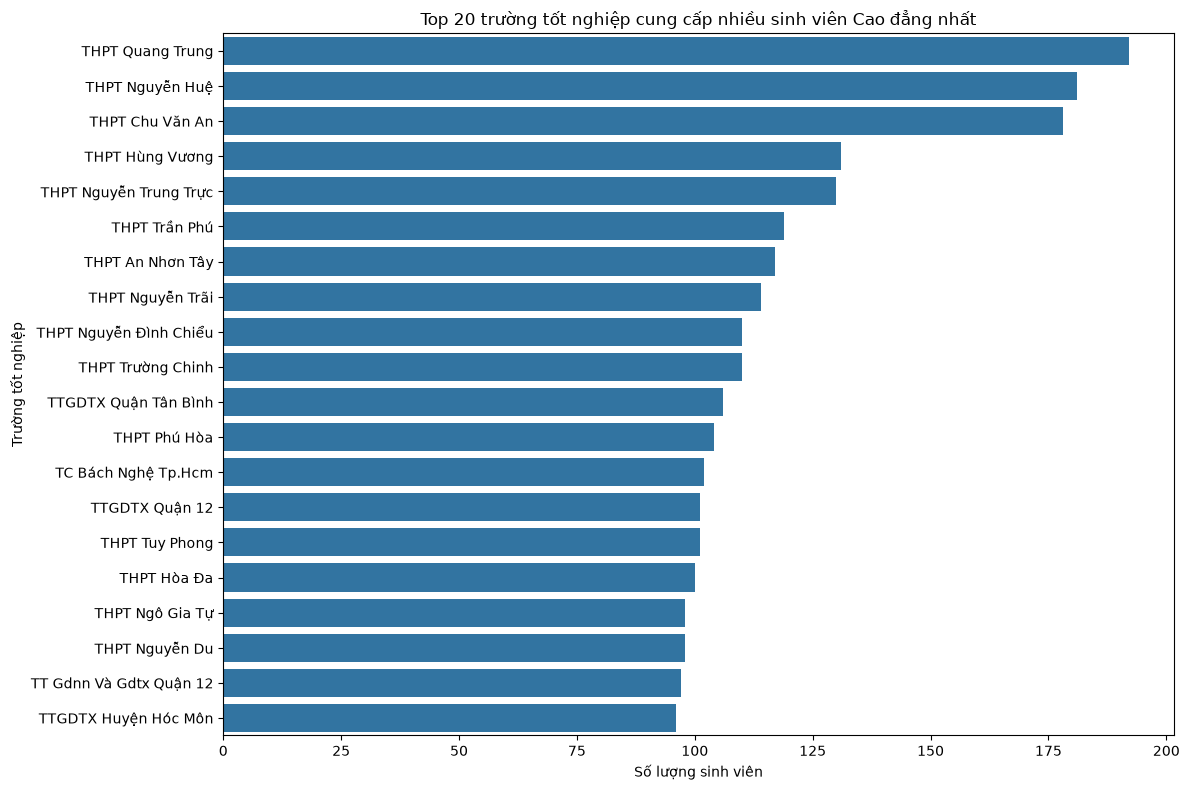

In [8]:
plt.figure(figsize=(12, 8))

sns.barplot(
    x=top20_school.values,
    y=top20_school.index
)

plt.title("Top 20 trường tốt nghiệp cung cấp nhiều sinh viên Cao đẳng nhất")
plt.xlabel("Số lượng sinh viên")
plt.ylabel("Trường tốt nghiệp")

plt.tight_layout()
plt.show()

In [9]:
top10_school = (
    df_school["Trường tốt nghiệp"]
    .value_counts()
    .head(10)
    .index
)

school_year = (
    df_school[
        df_school["Trường tốt nghiệp"].isin(top10_school)
    ]
    .groupby(["Khóa học", "Trường tốt nghiệp"])
    .size()
    .reset_index(name="Số lượng")
)

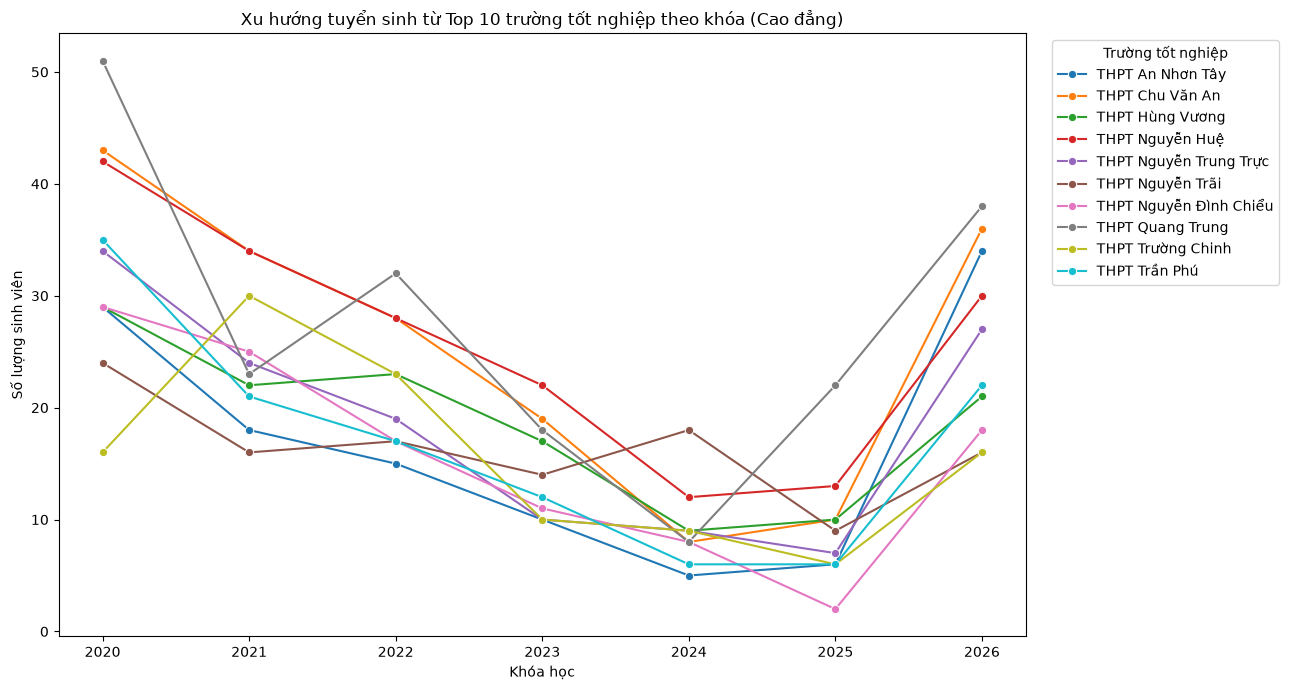

In [10]:
plt.figure(figsize=(13, 7))

sns.lineplot(
    data=school_year,
    x="Khóa học",
    y="Số lượng",
    hue="Trường tốt nghiệp",
    marker="o"
)

plt.title("Xu hướng tuyển sinh từ Top 10 trường tốt nghiệp theo khóa (Cao đẳng)")
plt.xlabel("Khóa học")
plt.ylabel("Số lượng sinh viên")

plt.legend(
    title="Trường tốt nghiệp",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

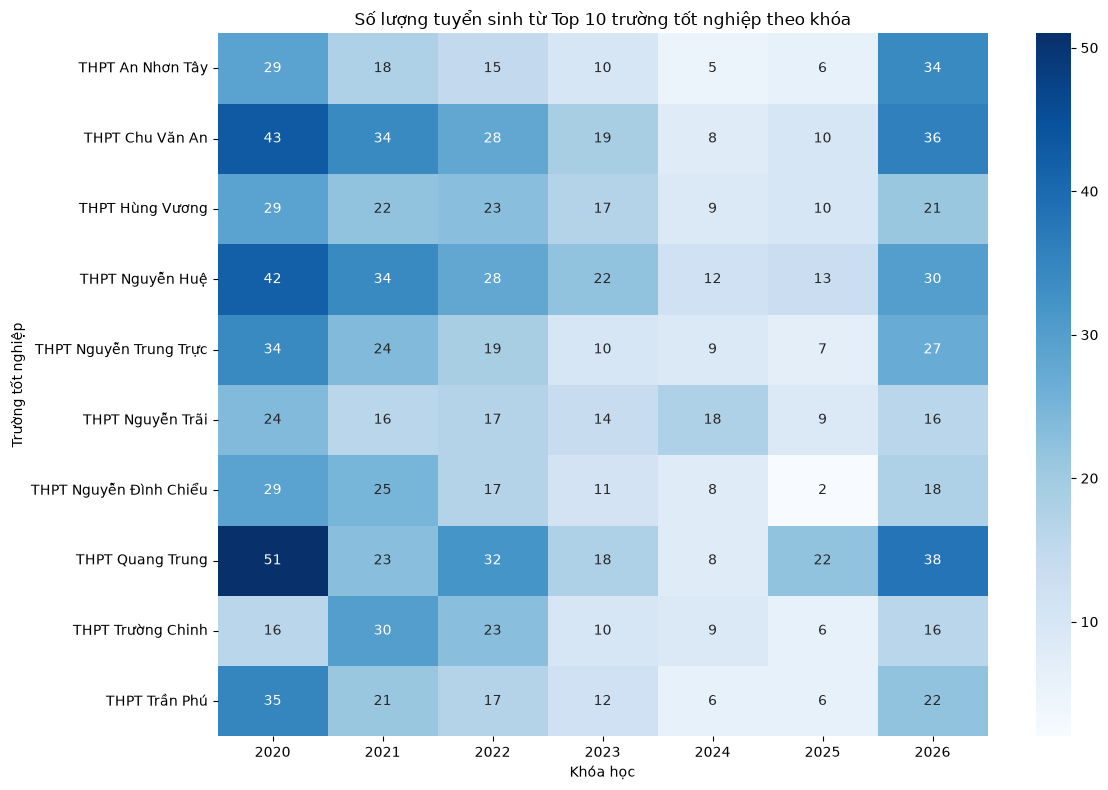

In [11]:
school_year_heatmap = (
    school_year
    .pivot(
        index="Trường tốt nghiệp",
        columns="Khóa học",
        values="Số lượng"
    )
    .fillna(0)
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    school_year_heatmap,
    annot=True,
    fmt=".0f",
    cmap="Blues"
)

plt.title("Số lượng tuyển sinh từ Top 10 trường tốt nghiệp theo khóa")
plt.xlabel("Khóa học")
plt.ylabel("Trường tốt nghiệp")

plt.tight_layout()
plt.show()

In [12]:
top10_school = (
    df_school["Trường tốt nghiệp"]
    .value_counts()
    .head(10)
    .index
)

temp = df_school[
    df_school["Trường tốt nghiệp"].isin(top10_school)
].copy()

In [13]:
school_major = (
    temp
    .groupby(["Ngành", "Trường tốt nghiệp"])
    .size()
    .unstack(fill_value=0)
)

# % trong từng trường
school_major_pct = (
    school_major
    .div(school_major.sum(axis=0), axis=1)
    * 100
)

In [14]:
top10_major = (
    df_school["Ngành"]
    .value_counts()
    .head(10)
    .index
)

temp["Nhóm ngành"] = temp["Ngành"].where(
    temp["Ngành"].isin(top10_major),
    "Các ngành khác"
)

school_major = (
    temp
    .groupby(["Nhóm ngành", "Trường tốt nghiệp"])
    .size()
    .unstack(fill_value=0)
)

school_major_pct = (
    school_major
    .div(school_major.sum(axis=0), axis=1)
    * 100
)

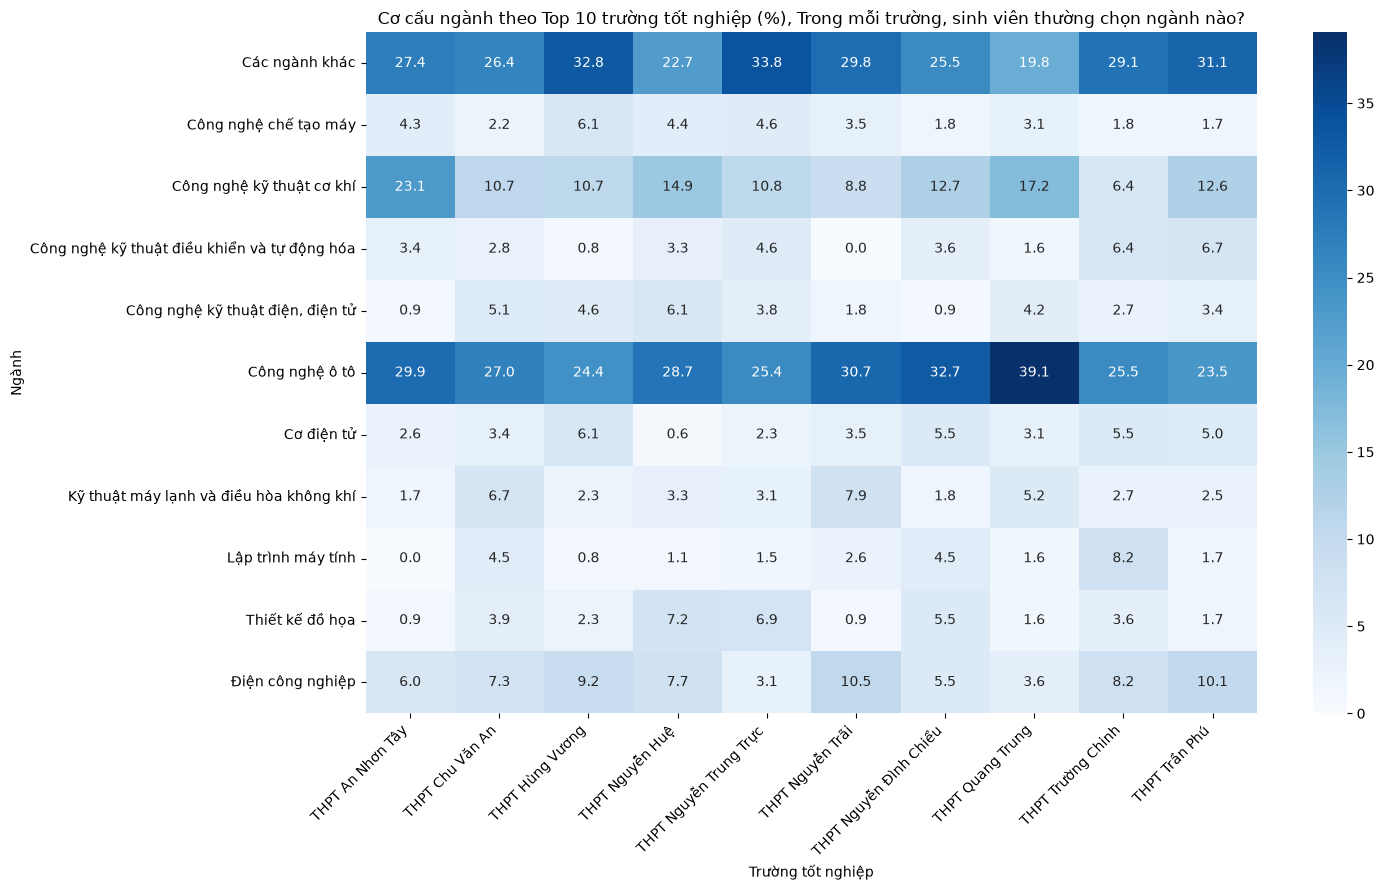

In [15]:
plt.figure(figsize=(15, 9))

sns.heatmap(
    school_major_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("Cơ cấu ngành theo Top 10 trường tốt nghiệp (%), Trong mỗi trường, sinh viên thường chọn ngành nào?")
plt.xlabel("Trường tốt nghiệp")
plt.ylabel("Ngành")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [16]:
# Không giới hạn Top 10 trường
school_major_all = (
    df_school
    .groupby(["Trường tốt nghiệp", "Ngành"])
    .size()
    .reset_index(name="Số lượng")
)

# Tổng sinh viên từ mỗi trường
school_total = (
    df_school
    .groupby("Trường tốt nghiệp")
    .size()
    .rename("Tổng")
    .reset_index()
)

school_major_all = school_major_all.merge(
    school_total,
    on="Trường tốt nghiệp"
)

school_major_all["Tỷ lệ (%)"] = (
    school_major_all["Số lượng"]
    / school_major_all["Tổng"]
    * 100
)

In [17]:
# Chỉ giữ:
# - Trường có ít nhất 20 sinh viên
# - Ngành chiếm trên 10% sinh viên của trường đó
result = school_major_all[
    (school_major_all["Tổng"] >= 50) &
    (school_major_all["Tỷ lệ (%)"] > 10)
].sort_values(
    ["Trường tốt nghiệp", "Tỷ lệ (%)"],
    ascending=[True, False]
)

for school, group in result.groupby("Trường tốt nghiệp"):
    total = group["Tổng"].iloc[0]

    print(f"\n{school} (Tổng: {total} SV)")

    for _, row in group.iterrows():
        print(
            f"   {row['Ngành']}: "
            f"{row['Tỷ lệ (%)']:.1f}% "
            f"({row['Số lượng']}/{row['Tổng']})"
        )


TC Bách Nghệ Tp.Hcm (Tổng: 102 SV)
   Công nghệ ô tô: 21.6% (22/102)
   Điện công nghiệp: 13.7% (14/102)
   Công nghệ kỹ thuật cơ khí: 10.8% (11/102)

TC Ktkt Quận 12 (Tổng: 51 SV)
   Công nghệ ô tô: 39.2% (20/51)
   Kỹ thuật máy lạnh và điều hòa không khí: 13.7% (7/51)

TC Nghề Củ Chi (Tổng: 77 SV)
   Công nghệ ô tô: 29.9% (23/77)
   Điện công nghiệp: 16.9% (13/77)
   Công nghệ kỹ thuật cơ khí: 13.0% (10/77)
   Công nghệ kỹ thuật máy tính: 10.4% (8/77)

THCS Thpt Hồng Hà (Tổng: 56 SV)
   Công nghệ ô tô: 30.4% (17/56)

THCS&THPT Long Hựu Đông (Tổng: 55 SV)
   Công nghệ ô tô: 20.0% (11/55)
   Công nghệ kỹ thuật cơ khí: 14.5% (8/55)
   Điện công nghiệp: 12.7% (7/55)

THPT An Nhơn Tây (Tổng: 117 SV)
   Công nghệ ô tô: 29.9% (35/117)
   Công nghệ kỹ thuật cơ khí: 23.1% (27/117)

THPT Bình Hưng Hòa (Tổng: 65 SV)
   Công nghệ ô tô: 16.9% (11/65)

THPT Bình Tân (Tổng: 78 SV)
   Công nghệ ô tô: 20.5% (16/78)
   Công nghệ kỹ thuật cơ khí: 12.8% (10/78)

THPT Chu Văn An (Tổng: 178 SV)
   Công n

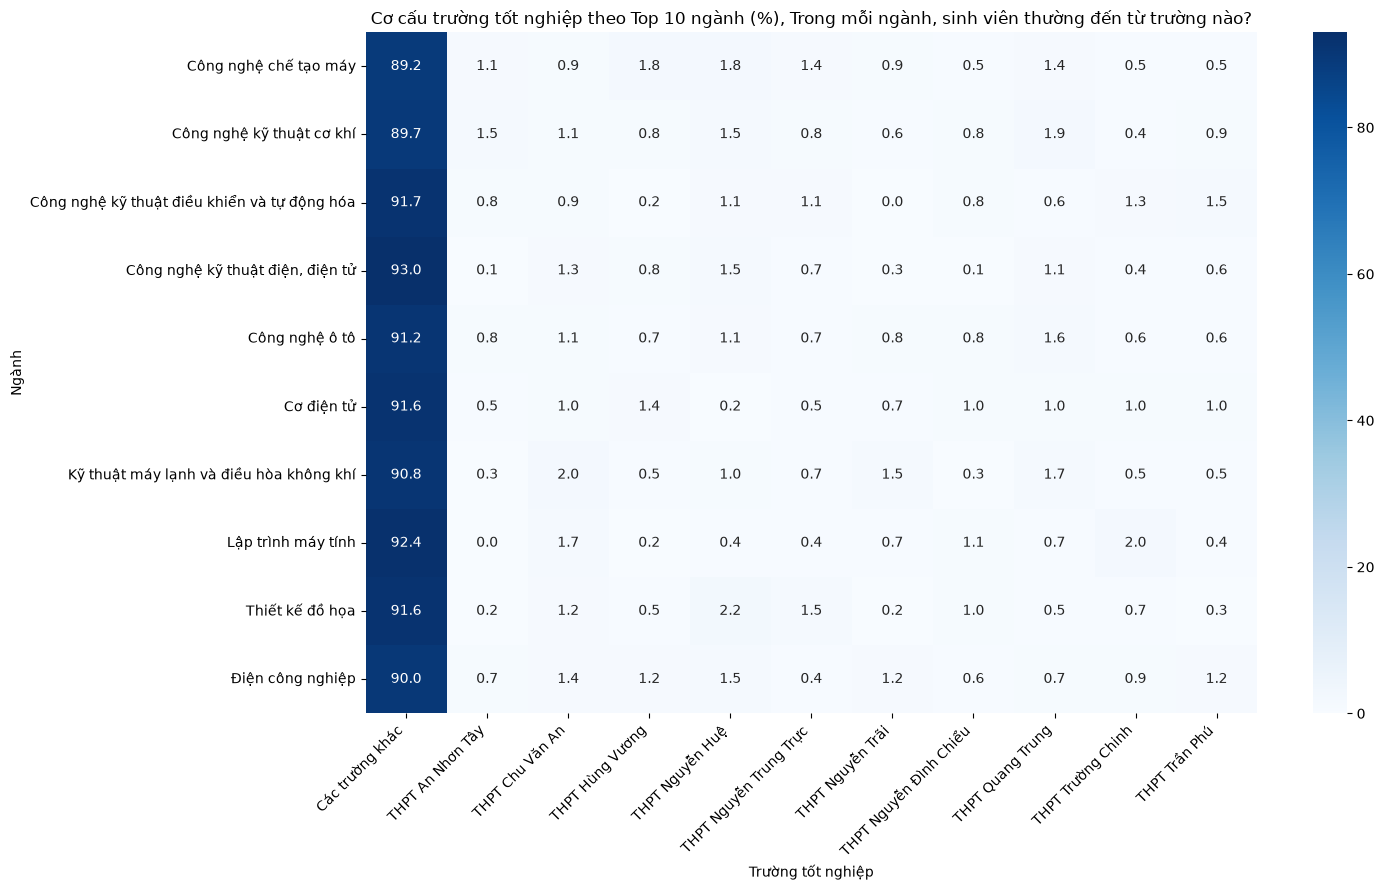

In [18]:
# Top 10 trường
top10_school = (
    df_school["Trường tốt nghiệp"]
    .value_counts()
    .head(10)
    .index
)

# Top 10 ngành
top10_major = (
    df_school["Ngành"]
    .value_counts()
    .head(10)
    .index
)

# Chỉ giữ Top 10 ngành
temp = df_school[
    df_school["Ngành"].isin(top10_major)
].copy()

# Các trường ngoài Top 10 -> "Các trường khác"
temp["Nhóm trường"] = temp["Trường tốt nghiệp"].where(
    temp["Trường tốt nghiệp"].isin(top10_school),
    "Các trường khác"
)

# Ngành × Trường
major_school = (
    temp
    .groupby(["Ngành", "Nhóm trường"])
    .size()
    .unstack(fill_value=0)
)

# % trong từng NGÀNH
# Mỗi hàng cộng thành 100%
major_school_pct = (
    major_school
    .div(major_school.sum(axis=1), axis=0)
    * 100
)

plt.figure(figsize=(15, 9))

sns.heatmap(
    major_school_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title(
    "Cơ cấu trường tốt nghiệp theo Top 10 ngành (%), "
    "Trong mỗi ngành, sinh viên thường đến từ trường nào?"
)

plt.xlabel("Trường tốt nghiệp")
plt.ylabel("Ngành")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [19]:
# Số sinh viên theo Ngành × Trường
major_school_all = (
    df_school
    .groupby(["Ngành", "Trường tốt nghiệp"])
    .size()
    .unstack(fill_value=0)
)

# % trường trong từng ngành
# Chia theo tổng của ROW (mỗi ngành)
major_school_all_pct = (
    major_school_all
    .div(major_school_all.sum(axis=1), axis=0)
    * 100
)

print("Trong mỗi ngành, sinh viên đến từ những trường nào?")

for major in major_school_all_pct.index:

    # Tổng số sinh viên của ngành
    total = major_school_all.loc[major].sum()

    # Chỉ xét ngành có ít nhất 30 sinh viên
    if total < 30:
        continue

    # Các trường chiếm > 10% nguồn sinh viên của ngành
    result = (
        major_school_all_pct.loc[major]
        [major_school_all_pct.loc[major] > 1]
        .sort_values(ascending=False)
    )

    if len(result) > 0:
        print(f"\n{major} - Tổng: {total} SV")

        for school, pct in result.items():
            n = major_school_all.loc[major, school]

            print(
                f"  {school}: {pct:.1f}% ({n}/{total} SV)"
            )

Trong mỗi ngành, sinh viên đến từ những trường nào?

Bảo trì hệ thống thiết bị công nghiệp - Tổng: 47 SV
  THPT Trảng Bàng: 14.9% (7/47 SV)
  THPT Nguyễn Trung Trực: 6.4% (3/47 SV)
  THPT Văn Hiến: 4.3% (2/47 SV)
  THPT Kiệm Tân: 4.3% (2/47 SV)
  CAO Đẳng Nghề Phú Yên: 2.1% (1/47 SV)
  THPT Chơn Thành: 2.1% (1/47 SV)
  THPT Chu Văn An: 2.1% (1/47 SV)
  THPT An Nhơn Tây: 2.1% (1/47 SV)
  TH, Thcs Và Thpt Ngô Thời Nhiệm: 2.1% (1/47 SV)
  THPT Hậu Nghĩa: 2.1% (1/47 SV)
  THPT Kiên Lương: 2.1% (1/47 SV)
  THPT Hùng Vương: 2.1% (1/47 SV)
  THPT Dầu Giây: 2.1% (1/47 SV)
  THPT Lê Hồng Phong - Di Linh: 2.1% (1/47 SV)
  THPT Lương Thế Vinh: 2.1% (1/47 SV)
  THPT Nguyễn Du: 2.1% (1/47 SV)
  THPT Nguyễn Công Trứ: 2.1% (1/47 SV)
  THPT Nguyễn Hiền: 2.1% (1/47 SV)
  THPT Nguyễn Đình Chiểu: 2.1% (1/47 SV)
  THPT Long Thới: 2.1% (1/47 SV)
  THPT Gò Công Đông: 2.1% (1/47 SV)
  THPT Phước Bửu: 2.1% (1/47 SV)
  THPT Phan Bội Châu: 2.1% (1/47 SV)
  THPT Thanh Đa: 2.1% (1/47 SV)
  THPT Phước Hòa: 2.1% (1

In [20]:
#Top 5 trường nguồn cộng lại chiếm bao nhiêu % của từng ngành

In [21]:
# Số SV theo Ngành × Trường
major_school_count = (
    df_school
    .groupby(["Ngành", "Trường tốt nghiệp"])
    .size()
    .reset_index(name="Số lượng")
)

# Tổng SV của từng ngành
major_total = (
    df_school
    .groupby("Ngành")
    .size()
    .rename("Tổng")
)

# Sắp xếp trường từ nhiều -> ít trong từng ngành
major_school_count = major_school_count.sort_values(
    ["Ngành", "Số lượng"],
    ascending=[True, False]
)

# Lấy Top 5 trường của mỗi ngành
top5 = (
    major_school_count
    .groupby("Ngành")
    .head(5)
    .copy()
)

# Thêm tổng SV ngành
top5["Tổng"] = top5["Ngành"].map(major_total)

# % từng trường
top5["Tỷ lệ (%)"] = (
    top5["Số lượng"] / top5["Tổng"] * 100
)

# Tổng số SV từ Top 5 trường
top5_summary = (
    top5
    .groupby("Ngành")
    .agg(
        Top5_SV=("Số lượng", "sum"),
        Tổng=("Tổng", "first")
    )
)

top5_summary["Top 5 (%)"] = (
    top5_summary["Top5_SV"]
    / top5_summary["Tổng"]
    * 100
).round(1)

# Chỉ xét ngành có >= 30 SV
top5_summary = top5_summary[
    top5_summary["Tổng"] >= 30
].sort_values("Top 5 (%)", ascending=False)

print("Top 5 trường nguồn cộng lại chiếm bao nhiêu % của từng ngành")
display(top5_summary)

Top 5 trường nguồn cộng lại chiếm bao nhiêu % của từng ngành


,Top5_SV,Tổng,Top 5 (%)
Ngành,,,
Bảo trì hệ thống thiết bị công nghiệp,15,47,31.9
Tin học ứng dụng,12,45,26.7
Lắp đặt thiết bị lạnh,17,64,26.6
Tiếng Hàn Quốc,9,46,19.6
Công nghệ may,18,99,18.2
Cắt gọt kim loại,23,136,16.9
Điện tử công nghiệp,20,125,16.0
Kỹ thuật làm bánh,17,108,15.7
Quản trị lữ hành,5,32,15.6


In [22]:
print("Top 5 trường nguồn cộng lại chiếm bao nhiêu % của từng ngành")
for major in top5_summary.index:

    group = top5[top5["Ngành"] == major]
    total = group["Tổng"].iloc[0]

    top5_n = group["Số lượng"].sum()
    top5_pct = top5_n / total * 100

    print(
        f"\n{major} - Tổng: {total} SV "
        f"| Top 5: {top5_n} SV ({top5_pct:.1f}%)"
    )

    for _, row in group.iterrows():
        print(
            f"  {row['Trường tốt nghiệp']}: "
            f"{row['Số lượng']} SV "
            f"({row['Tỷ lệ (%)']:.1f}%)"
        )

Top 5 trường nguồn cộng lại chiếm bao nhiêu % của từng ngành

Bảo trì hệ thống thiết bị công nghiệp - Tổng: 47 SV | Top 5: 15 SV (31.9%)
  THPT Trảng Bàng: 7 SV (14.9%)
  THPT Nguyễn Trung Trực: 3 SV (6.4%)
  THPT Kiệm Tân: 2 SV (4.3%)
  THPT Văn Hiến: 2 SV (4.3%)
  CAO Đẳng Nghề Phú Yên: 1 SV (2.1%)

Tin học ứng dụng - Tổng: 45 SV | Top 5: 12 SV (26.7%)
  THPT Nguyễn Văn Cừ: 3 SV (6.7%)
  TT Gdnn Và Gdtx Huyện Củ Chi: 3 SV (6.7%)
  THPT Nguyễn Thị Định: 2 SV (4.4%)
  THPT Vĩnh Lộc B: 2 SV (4.4%)
  TT Gdnn Và Gdtx Quận Bình Tân: 2 SV (4.4%)

Lắp đặt thiết bị lạnh - Tổng: 64 SV | Top 5: 17 SV (26.6%)
  THPT Chu Văn An: 6 SV (9.4%)
  THPT Quang Trung: 4 SV (6.2%)
  THPT Nguyễn Trung Trực: 3 SV (4.7%)
  THCS&THPT Long Cang: 2 SV (3.1%)
  THCS&THPT Phú Thạnh: 2 SV (3.1%)

Tiếng Hàn Quốc - Tổng: 46 SV | Top 5: 9 SV (19.6%)
  THCS Và Thpt Thạnh Thắng: 2 SV (4.3%)
  THPT An Nhơn Tây: 2 SV (4.3%)
  THPT Huỳnh Thúc Kháng: 2 SV (4.3%)
  TT Gdnn Và Gdtx Quận 12: 2 SV (4.3%)
  PT Thực Hành Sư Phạm

In [23]:
#
#
#
# test trung cấp
#
#
#

In [24]:
# 1. Lọc dữ liệu Trung cấp
df_school_tc = df_clean[
    (df_clean["Bậc đào tạo"] == "Trung cấp") &
    (df_clean["Trường tốt nghiệp"].notna()) &
    (df_clean["Trường tốt nghiệp"] != "KHÔNG Xác Định")
].copy()

print("Số sinh viên Trung cấp có thông tin trường tốt nghiệp:", len(df_school_tc))
print("Số trường:", df_school_tc["Trường tốt nghiệp"].nunique())

Số sinh viên Trung cấp có thông tin trường tốt nghiệp: 4774
Số trường: 957


In [25]:
top20_school_tc = (
    df_school_tc["Trường tốt nghiệp"]
    .value_counts()
    .head(20)
)

display(top20_school_tc)

Trường tốt nghiệp
THCS Phan Bội Châu         146
THCS Ngô Quyền             116
THCS Lê Lợi                115
THCS Tân Bình              105
THCS Hoàng Hoa Thám         95
THCS Võ Văn Tần             88
THCS Lý Thường Kiệt         82
THCS Nguyễn Huệ             77
THCS Quang Trung            76
THCS Ngô Sĩ Liên            70
THCS Nguyễn Trãi            68
THCS Nguyễn Vĩnh Nghiệp     66
THCS Phạm Ngọc Thạch        62
THCS Thoại Ngọc Hầu         62
THCS Nguyễn Văn Trỗi        60
THCS Đoàn Thị Điểm          60
THCS Lê Quý Đôn             59
THCS Tân Phú Trung          59
THCS Âu Lạc                 58
THCS Trường Chinh           56
Name: count, dtype: int64

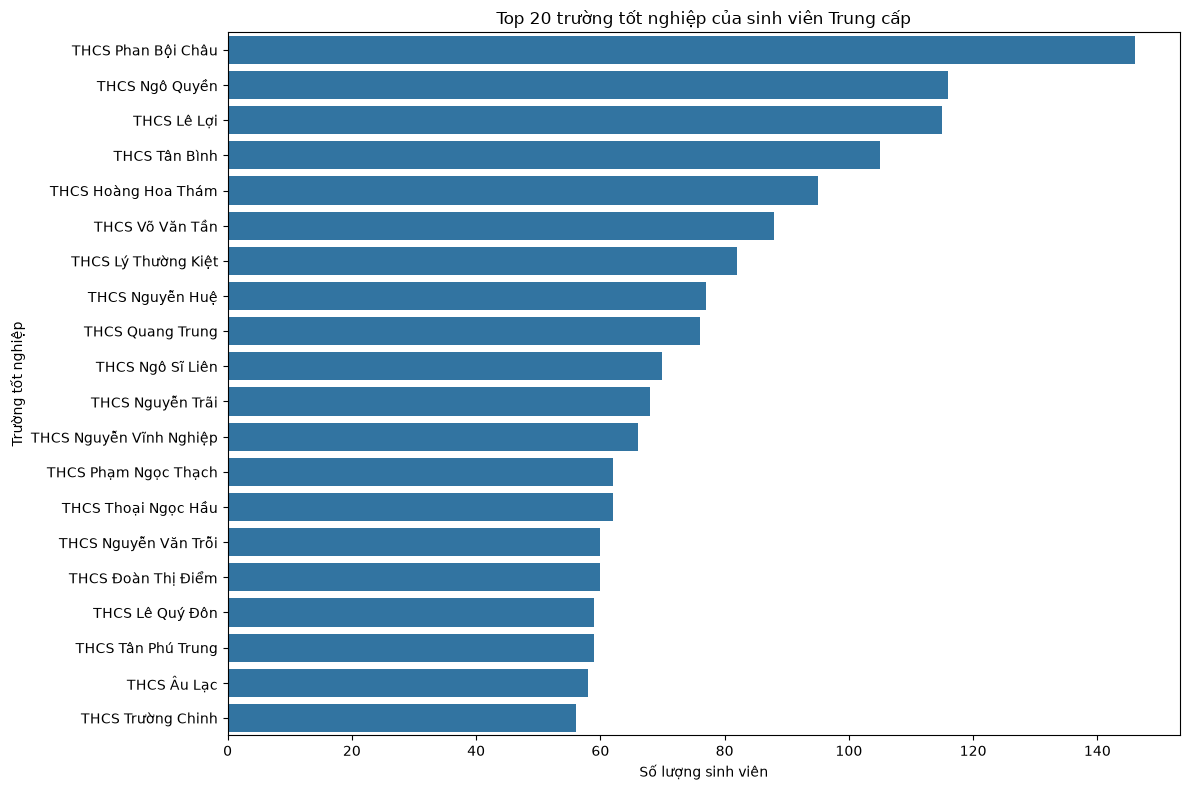

In [26]:
plt.figure(figsize=(12, 8))

sns.barplot(
    x=top20_school_tc.values,
    y=top20_school_tc.index
)

plt.title("Top 20 trường tốt nghiệp của sinh viên Trung cấp")
plt.xlabel("Số lượng sinh viên")
plt.ylabel("Trường tốt nghiệp")

plt.tight_layout()
plt.show()

In [27]:
top20_school_tc_pct = (
    top20_school_tc / len(df_school_tc) * 100
).round(2)

school_summary_tc = pd.DataFrame({
    "Số lượng": top20_school_tc,
    "Tỷ trọng (%)": top20_school_tc_pct
})

display(school_summary_tc)

,Số lượng,Tỷ trọng (%)
Trường tốt nghiệp,,
THCS Phan Bội Châu,146,3.06
THCS Ngô Quyền,116,2.43
THCS Lê Lợi,115,2.41
THCS Tân Bình,105,2.20
THCS Hoàng Hoa Thám,95,1.99
THCS Võ Văn Tần,88,1.84
THCS Lý Thường Kiệt,82,1.72
THCS Nguyễn Huệ,77,1.61
THCS Quang Trung,76,1.59


In [28]:
top10_school_tc = (
    df_school_tc["Trường tốt nghiệp"]
    .value_counts()
    .head(10)
    .index
)

school_year_tc = (
    df_school_tc[
        df_school_tc["Trường tốt nghiệp"].isin(top10_school_tc)
    ]
    .groupby(["Khóa học", "Trường tốt nghiệp"])
    .size()
    .reset_index(name="Số lượng")
)

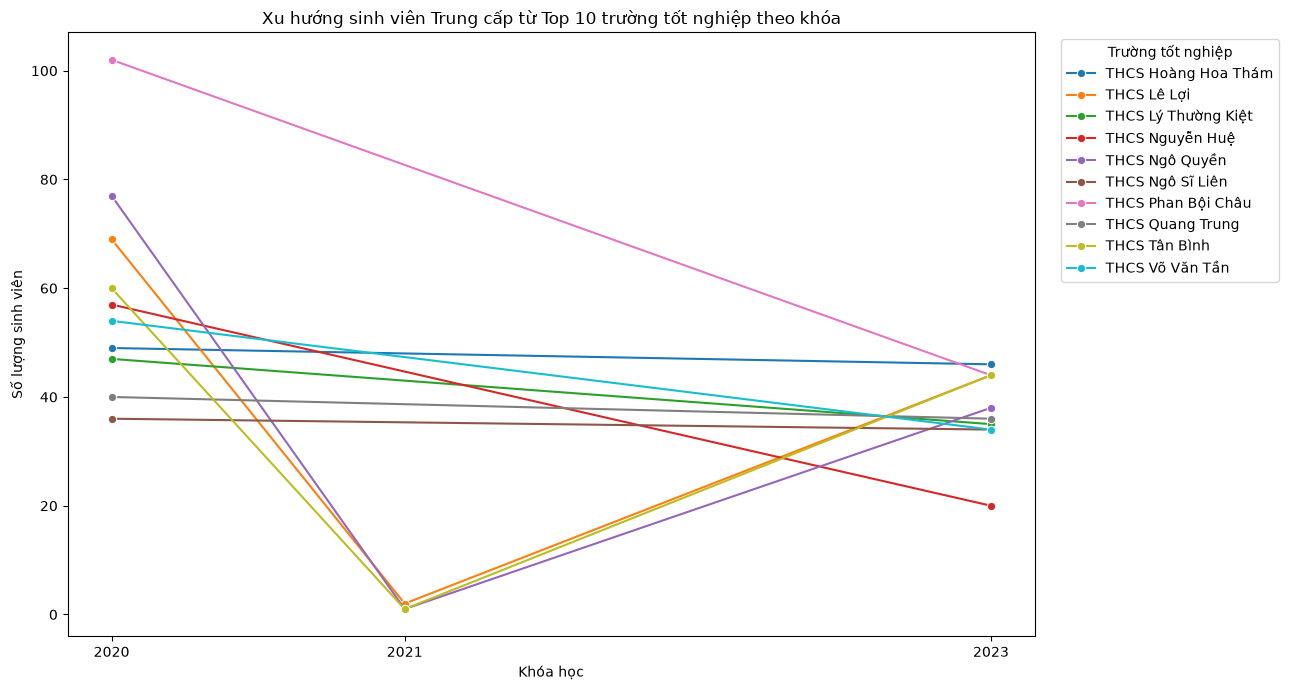

In [29]:
school_year_tc["Khóa học"] = school_year_tc["Khóa học"].astype(int)

plt.figure(figsize=(13, 7))

sns.lineplot(
    data=school_year_tc,
    x="Khóa học",
    y="Số lượng",
    hue="Trường tốt nghiệp",
    marker="o"
)

plt.title("Xu hướng sinh viên Trung cấp từ Top 10 trường tốt nghiệp theo khóa")
plt.xlabel("Khóa học")
plt.ylabel("Số lượng sinh viên")

# Chỉ hiện năm nguyên
plt.xticks(sorted(school_year_tc["Khóa học"].unique()))

plt.legend(
    title="Trường tốt nghiệp",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

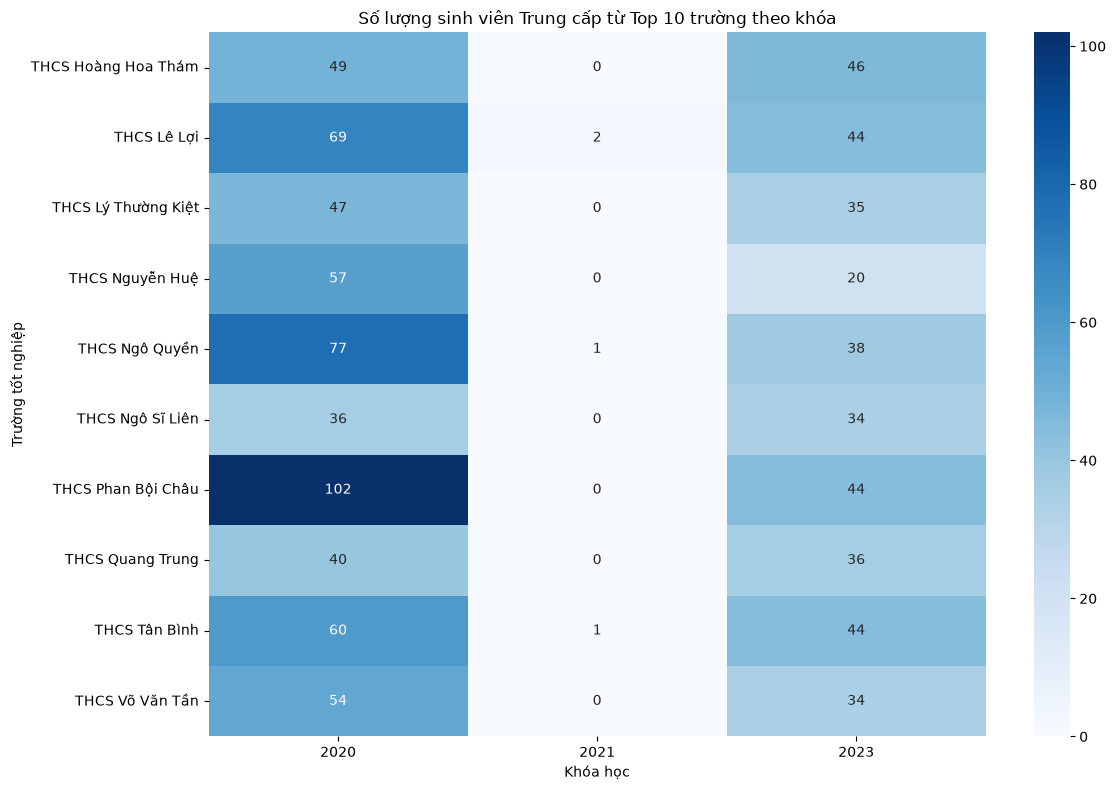

In [30]:
school_year_heatmap_tc = (
    school_year_tc
    .pivot(
        index="Trường tốt nghiệp",
        columns="Khóa học",
        values="Số lượng"
    )
    .fillna(0)
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    school_year_heatmap_tc,
    annot=True,
    fmt=".0f",
    cmap="Blues"
)

plt.title("Số lượng sinh viên Trung cấp từ Top 10 trường theo khóa")
plt.xlabel("Khóa học")
plt.ylabel("Trường tốt nghiệp")

plt.tight_layout()
plt.show()

In [31]:
check_tc_school = (
    df_clean[
        df_clean["Bậc đào tạo"] == "Trung cấp"
    ]
    .assign(
        Có_trường=lambda x:
            x["Trường tốt nghiệp"].notna()
            & (x["Trường tốt nghiệp"] != "KHÔNG Xác Định")
    )
    .groupby("Khóa học")
    .agg(
        Tổng=("Trường tốt nghiệp", "size"),
        Có_dữ_liệu=("Có_trường", "sum")
    )
)

check_tc_school["Missing"] = (
    check_tc_school["Tổng"]
    - check_tc_school["Có_dữ_liệu"]
)

check_tc_school["% Có dữ liệu"] = (
    check_tc_school["Có_dữ_liệu"]
    / check_tc_school["Tổng"]
    * 100
).round(1)

check_tc_school["% Missing"] = (
    check_tc_school["Missing"]
    / check_tc_school["Tổng"]
    * 100
).round(1)

display(check_tc_school)

,Tổng,Có_dữ_liệu,Missing,% Có dữ liệu,% Missing
Khóa học,,,,,
2020,3252,3089,163,95.0,5.0
2021,2090,64,2026,3.1,96.9
2022,2116,55,2061,2.6,97.4
2023,3149,1483,1666,47.1,52.9
2024,1882,20,1862,1.1,98.9
2025,805,13,792,1.6,98.4
2026,1064,50,1014,4.7,95.3
